In [1]:
# Importing packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Importing Data and Mainupulating

In [2]:
# Readind the CSV data
sales_data = pd.read_csv("electronic_store_sample_data.csv")

# Changing column type to appropriate one to decrease the memory usage
sales_data['Gender'] = sales_data['Gender'].astype('category')
sales_data['Loyalty Member'] = sales_data['Loyalty Member'].astype('category')
sales_data['Product Type'] = sales_data['Product Type'].astype('category')
sales_data['Rating'] = sales_data['Rating'].astype('int8')
sales_data['Age'] = sales_data['Age'].astype('int8')
sales_data['Order Status'] = sales_data['Order Status'].astype('category')
sales_data['Payment Method'] = sales_data['Payment Method'].astype('category')
sales_data['Shipping Type'] = sales_data['Shipping Type'].astype('category')
sales_data['Purchase Date'] = pd.to_datetime(sales_data['Purchase Date'])

# Adding new column with the month name
sales_data['Purchase Month'] = sales_data["Purchase Date"].dt.month_name()
sales_data['Purchase Month'] = sales_data['Purchase Month'].astype('category')

#### Task 1: Line Plot

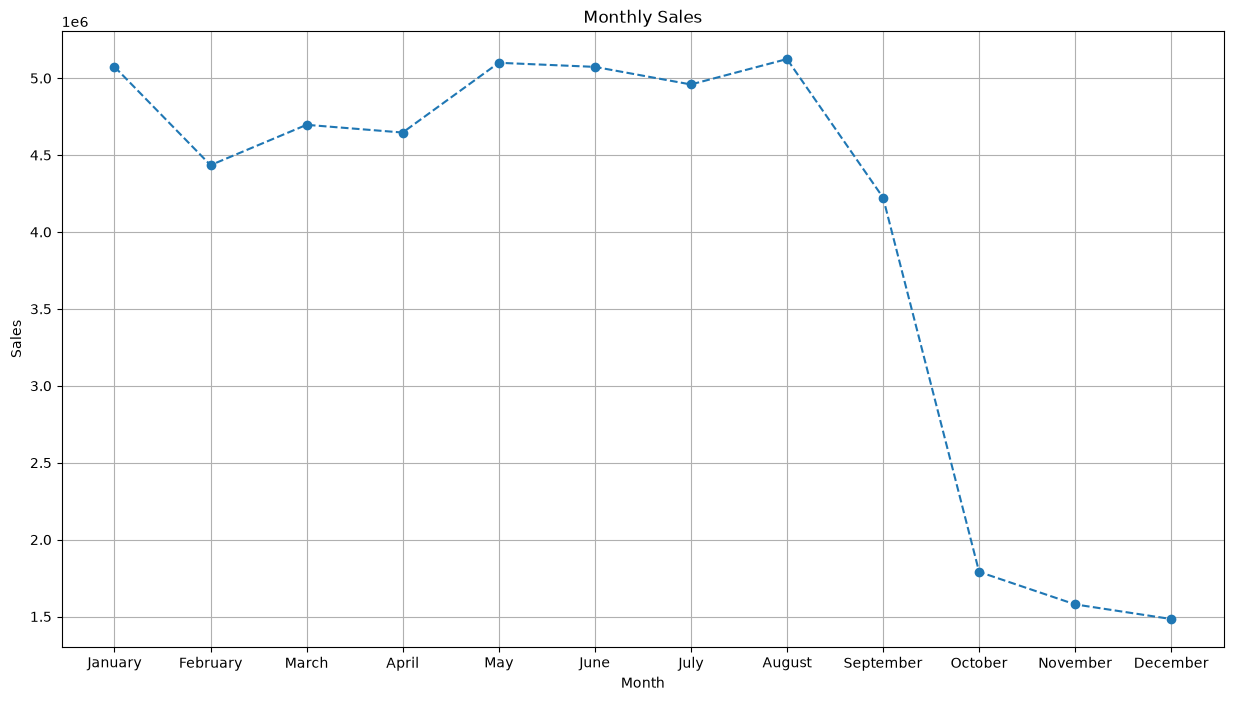

In [3]:
# Grouping data by month and summing up the total sales
line_data = sales_data.groupby("Purchase Month")["Total Price"].sum()

# Adding the categorial index and sorting them
line_data.index = pd.CategoricalIndex(line_data.index, categories=["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"], ordered=True)
line_data = line_data.sort_index()

# Ploting the Line Chart
plt.figure(figsize=(15,8))
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.plot(line_data.index, line_data.values, linestyle='--', marker='o')
plt.grid()
plt.show()

#### Task 2: Scatter Plot

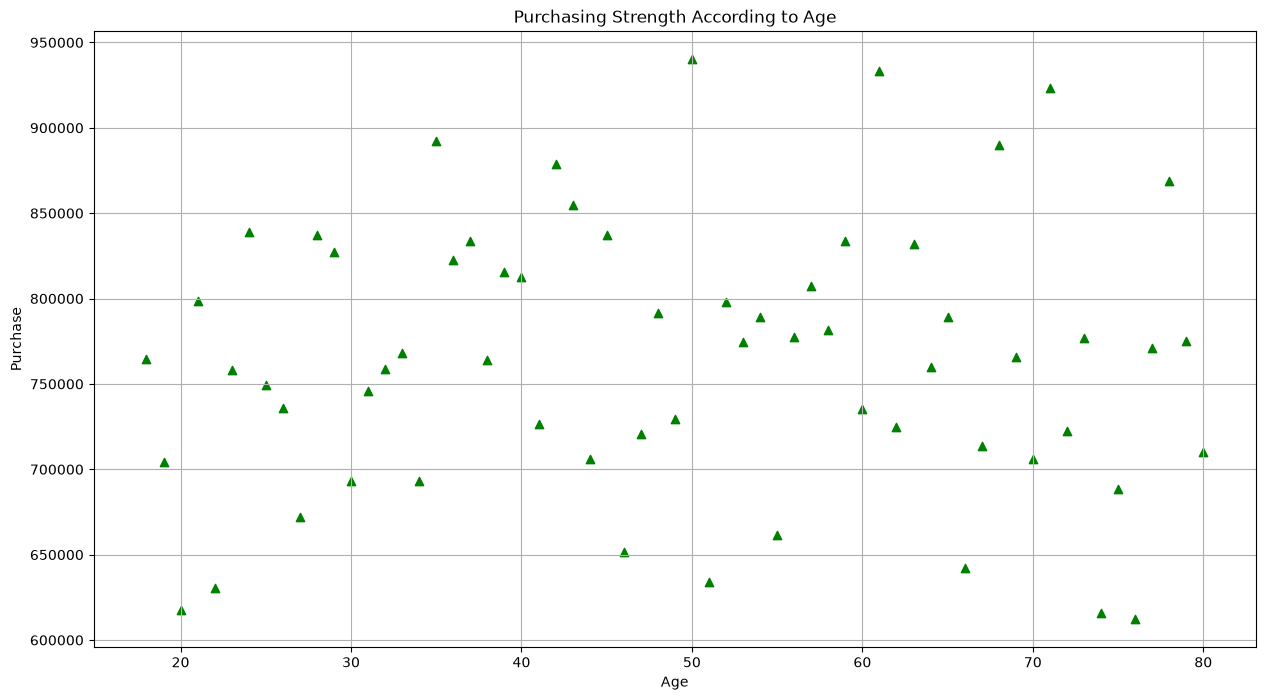

In [4]:
# Grouping data by Age and summing up the total sales
scatter_data = sales_data.groupby("Age")["Total Price"].sum()

# Ploting the Scatter Chart
plt.figure(figsize=(15,8))
plt.title('Purchasing Strength According to Age')
plt.xlabel('Age')
plt.ylabel('Purchase')
plt.scatter(scatter_data.index, scatter_data.values, marker="^", color="green")
plt.grid()
plt.show()

#### Task 3: Bar Plot

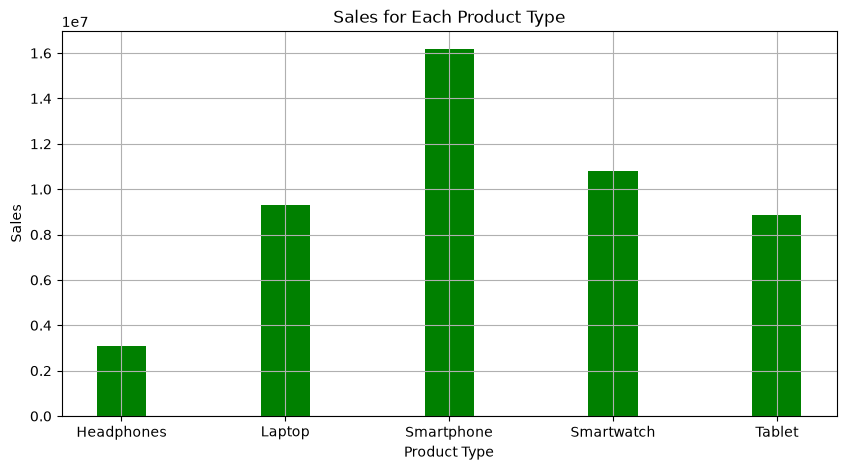

In [5]:
# Grouping data by Product Type and summing up the total sales
bar_data = sales_data.groupby("Product Type")["Total Price"].sum()

# Ploting the Bar Chart
plt.figure(figsize=(10,5))
plt.title('Sales for Each Product Type')
plt.xlabel('Product Type')
plt.ylabel('Sales')
plt.bar(bar_data.index, bar_data.values, width=0.3, color="green")
plt.grid()
plt.show()

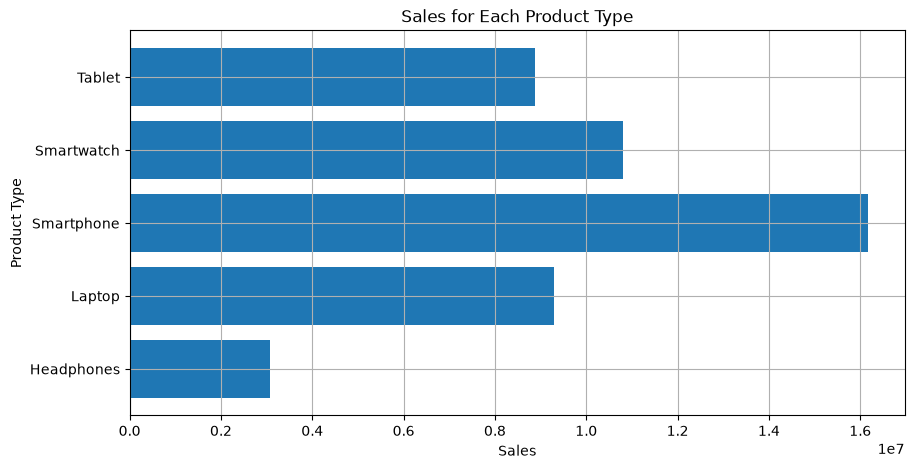

In [6]:
# Ploting the Horizontal Bar Chart
plt.figure(figsize=(10,5))
plt.title('Sales for Each Product Type')
plt.xlabel('Sales')
plt.ylabel('Product Type')
plt.barh(bar_data.index, bar_data.values)
plt.grid()
plt.show()

#### Task 4: Multi Bar Plot

In [7]:
# Grouping each unique Product Type based on Gender using for Multi and Stack Bar plot
smartphone_sales = sales_data[sales_data['Product Type'] == "Smartphone"]
tablet_sales = sales_data[sales_data['Product Type'] == "Tablet"]
laptop_sales = sales_data[sales_data['Product Type'] == "Laptop"]
smartwatch_sales = sales_data[sales_data['Product Type'] == "Smartwatch"]
headphone_sales = sales_data[sales_data['Product Type'] == "Headphones"]

smartphone_sales = smartphone_sales.groupby("Gender")["Total Price"].sum()
tablet_sales = tablet_sales.groupby("Gender")["Total Price"].sum()
laptop_sales = laptop_sales.groupby("Gender")["Total Price"].sum()
smartwatch_sales = smartwatch_sales.groupby("Gender")["Total Price"].sum()
headphone_sales = headphone_sales.groupby("Gender")["Total Price"].sum()

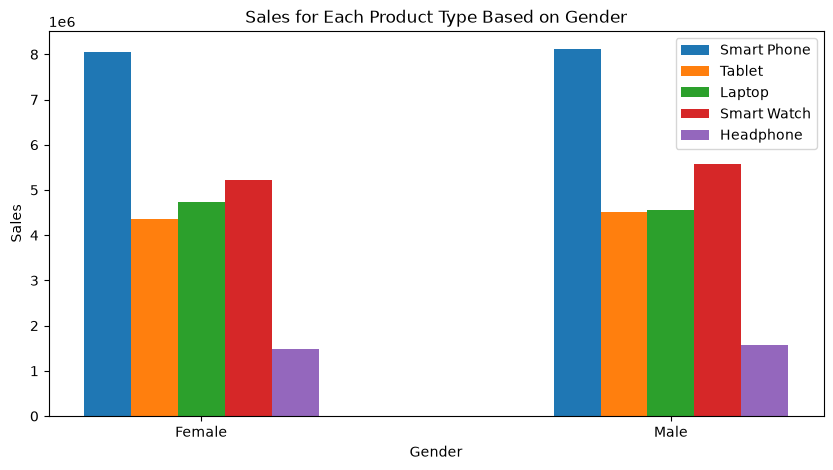

In [8]:
# Ploting the Multi Bar Chart
plt.figure(figsize=(10,5))
plt.title('Sales for Each Product Type Based on Gender')
plt.xlabel('Gender')
plt.ylabel('Sales')
plt.bar(np.arange(smartphone_sales.shape[0]) - 0.2, smartphone_sales.values, label="Smart Phone", width=0.1)
plt.bar(np.arange(tablet_sales.shape[0]) - 0.1, tablet_sales.values, label="Tablet", width=0.1)
plt.bar(np.arange(laptop_sales.shape[0]), laptop_sales.values, label="Laptop", width=0.1)
plt.bar(np.arange(smartwatch_sales.shape[0]) + 0.1, smartwatch_sales.values, label="Smart Watch", width=0.1)
plt.bar(np.arange(headphone_sales.shape[0]) + 0.2, headphone_sales.values, label="Headphone", width=0.1)
plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])
plt.legend()
plt.show()

#### Task 5: Stacked Bar Plot

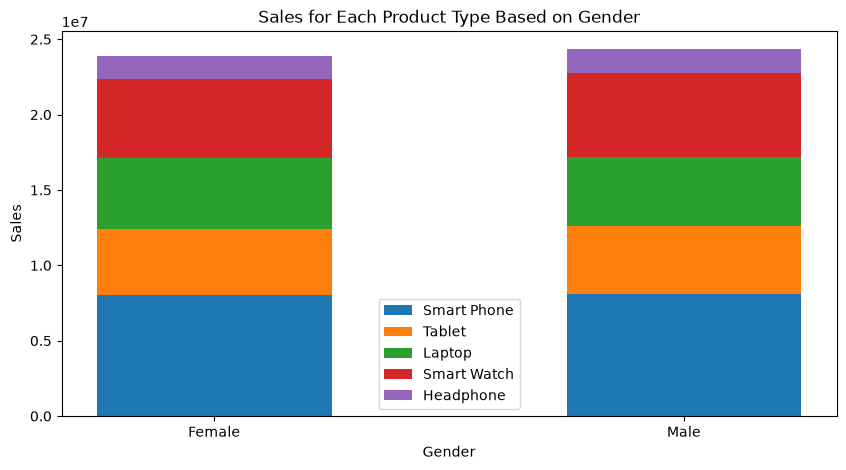

In [9]:
# Ploting the Stacked Bar Chart
plt.figure(figsize=(10,5))
plt.title('Sales for Each Product Type Based on Gender')
plt.xlabel('Gender')
plt.ylabel('Sales')
plt.bar(smartphone_sales.index, smartphone_sales.values, label="Smart Phone", width=0.5)
plt.bar(tablet_sales.index, tablet_sales.values, label="Tablet", bottom=smartphone_sales.values, width=0.5)
plt.bar(laptop_sales.index, laptop_sales.values, label="Laptop", bottom=(smartphone_sales.values + tablet_sales.values), width=0.5)
plt.bar(smartwatch_sales.index, smartwatch_sales.values, label="Smart Watch", bottom=(smartphone_sales.values + tablet_sales.values + laptop_sales.values), width=0.5)
plt.bar(headphone_sales.index, headphone_sales.values, label="Headphone", bottom=(smartphone_sales.values + tablet_sales.values + laptop_sales.values + smartwatch_sales.values), width=0.5)
plt.xticks(ticks=[0, 1], labels=['Female', 'Male'])
plt.legend()
plt.show()

#### Task 6: Hist Plot

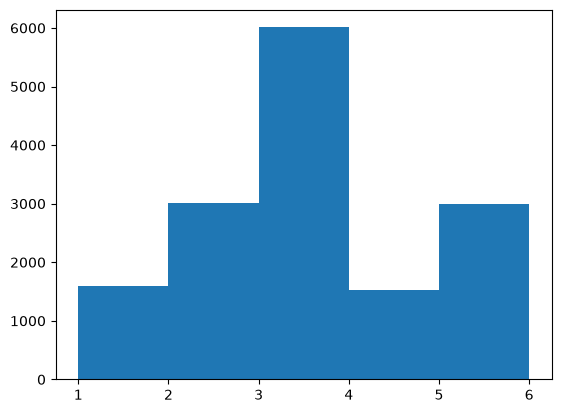

In [10]:
# Ploting the Hist Chart
plt.hist(sales_data["Rating"], bins=[1,2,3,4,5,6])
plt.show()

#### Task 7: Pie Plot

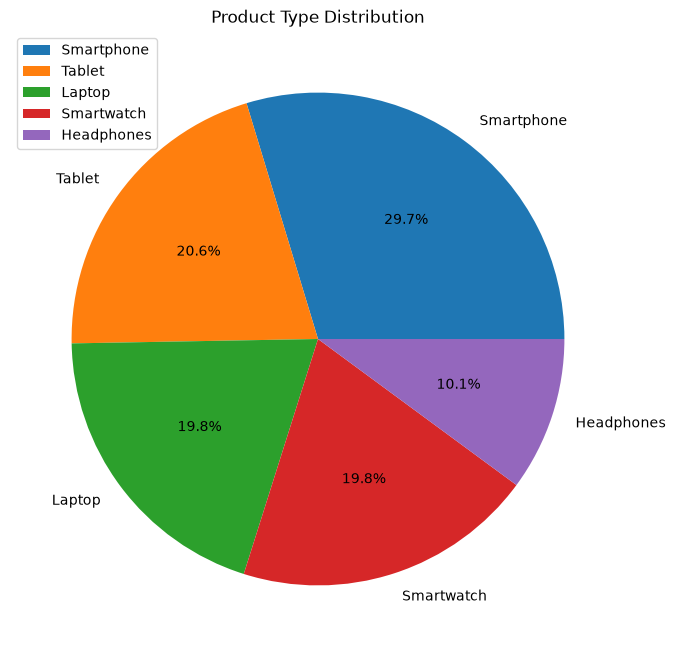

In [11]:
# Ploting the Pie Chart
pie_data = sales_data["Product Type"].value_counts()
plt.figure(figsize=(8,8))
plt.title("Product Type Distribution")
plt.pie(pie_data, labels=pie_data.index, autopct="%.1f%%")
plt.legend()
plt.show()